In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("Lab_6_simulating_quarter_car.ipynb")

# Lab 6: Simulating a quarter car

Slides for the lab: https://docs.google.com/presentation/d/1jDIVbp7EkyqVJJCpXnkg9KQl6stHF9WohauL1Lnr3YM/edit?usp=sharing 

In the previous lab, you wrote code to draw a quarter car, which we used to animate the quarter car. In this lab, we will work on simulating the quarter car as a dynamic system so we can animate the car driving down arbitrary roads.

See the lecture notes for an image of the dynamic model of a quarter car.

In the diagram, $m_s$ is the mass of the car body (sprung mass), $m_u$ is the mass of the wheel itself (unsprung mass), $c_s$ is the damping constant of the suspension, $k_s$ is the spring constant of the suspension, and $k_t$ is the spring constant of the tire.

These properties, along with the shape of the road itself, influence the simulation of the quarter car.

Bring your **`car.py`** from Lab 5 (`Week_5_classes/car.py`). This notebook imports it from that folder. You will add the physics parameters, state-space matrices, and `simulate` method to `QuarterCar` in that file (look for `# TODO Lab 6`).



In this lab, we will be using a _state space model_ to simulate our quarter car. State space models use state variables to describe a system by a set of differential equations. The output of our system will be $y_s$ and $y_u$, the $y$ positions of the sprung and unsprung masses, over time. We will then use those outputs to animate the quarter car driving down the road.

In [2]:
# Imports
import sys
from pathlib import Path

import numpy as np
from scipy.stats import gamma
from scipy.signal import StateSpace, lsim
import matplotlib.pyplot as plt
import matplotlib.animation as animation
# Enable animations to work
%matplotlib widget

# car.py lives with Lab 5 / HW 2 in Week_5_classes
# code copied from discord software setup to fix Quarter car import issue
if str(Path.cwd().parent/"Week_5_classes") not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent/"Week_5_classes"))
%load_ext autoreload
%autoreload 2
try:
    from Week_5_classes.car import QuarterCar
except:
    from car import QuarterCar


## Part 1: Defining a road as input to the model

Before describing the state space model itself, let's discuss the input to the model: A road. The input to the state space system is $y_r$, which is the y coordinate of the road the car is riding on over time. We are working in two dimensions, so our road will be a simple line.

But in the real world, the y coordinate of the road depends on the x coordinate of the car's location, which, over time, changes in accordance with the car's velocity, which may itself change due to external input, gravity, etc.

To keep our system simple, we will model the car as traveling with a _constant velocity in the x direction_. The road shape and the state space system itself will have no impact on the car's velocity. With a constant velocity in the x direction, we can easily determine the car's x coordinate at a given time point, and use that to determine the road's y coordinate at that location.

Let's start by plotting a semi-interesting line with an angular 'bump' in it.

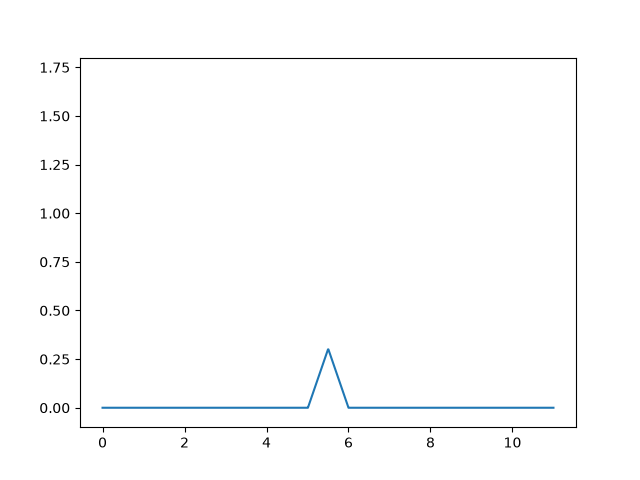

In [3]:
# Flat section, 5 meters long.
x_r_1 = [0, 5]
y_r_1 = [0, 0]

# Bump going up, 0.3 meters high
x_r_2 = [5.01, 5.5]
y_r_2 = [0, 0.3]

# Bump going down
x_r_3 = [5.51, 6.0]
y_r_3 = [0.3, 0]

# Flat section
x_r_4 = [6.01, 11]
y_r_4 = [0, 0]

X_r = np.concatenate((x_r_1, x_r_2, x_r_3, x_r_4))
Y_r = np.concatenate((y_r_1, y_r_2, y_r_3, y_r_4))

fig, axs = plt.subplots()
axs.plot(X_r, Y_r)
# Average height of car is ~1.8m.
axs.set_ylim(-0.1, 1.8)

plt.show()

## Part 1, continued

Now that we have this line, we need to make it work as input to our state space system. While the real world is continuous, computers are discrete. Computers evaluate the system at specific time points, with specific-sized time steps. If the time steps are too small, the simulation will be more accurate (capturing all of the contours of the road), but will take a very long time to complete. If the time steps are too big, the simulation will be fast, but inaccurate -- it might miss an important road feature.

We can explore this phenomenon by evaluating our bump with different sized time steps. We will use Numpy's `np.interp` function to interpolate the line at specific time points.

Let's first interpolate the line every 10ms.

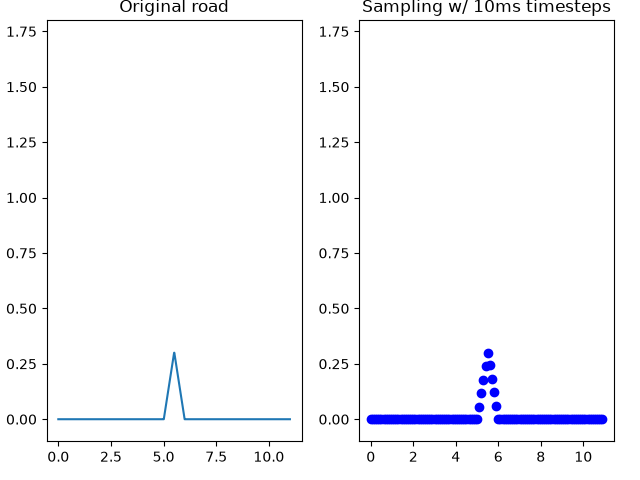

In [4]:
# Car is traveling at 10 m/s.
velocity = 10
# Evaluate the car's position every 10ms (10ms time step)
dt = 10
# Distance traveled each time step, in meters.
# dt is in milliseconds, so we convert it to seconds by dividing by 1000.
x_dt = velocity * (dt / 1000)
# X_r[-1] is shorthand for 'the last item in X_r', which is the last x coordinate in th road.
X_c = np.arange(0, X_r[-1], x_dt)
# np.interp allows us to interpolate a line at specific x coordinates!
Y_c = np.interp(X_c, X_r, Y_r)

# Plot these points.
fig, axs = plt.subplots(1,2)
# Prevent plot titles from overlaying other plots.
fig.tight_layout()
# Average height of car is ~1.8m.
axs[0].set_ylim(-0.1, 1.8)
axs[1].set_ylim(-0.1, 1.8)

axs[0].plot(X_r, Y_r)
axs[0].set_title("Original road")
# Plot points for car position -- blue circles
axs[1].plot(X_c, Y_c, 'bo')
axs[1].set_title("Sampling w/ 10ms timesteps")

plt.show()

## Part 1, cont
With `dt` set to `10ms`, the interpolated road still looks like our road. But what happens if `dt` is too large?

Let's first define a function to interpolate a line with a given car `velocity` and `dt` so we can experiment easily with different `dt` values.

In [5]:
def interpolate_road(X_r, Y_r, velocity, dt):
    """
    Interpolate the road (X_r and Y_r) for a car traveling with
    the given velocity (in m/s) at timestamps every dt milliseconds.
    @param X_r numpy array containing the X coordinates of the road (in meters)
    @param Y_r numpy array containing the Y coordinates of the road (in meters)
    @param velocity of the car in m/s
    @param dt Change in time in milliseconds between interpolation points.
    @return (X, Y) of the interpolated road, as a Python tuple
    """
    # GUIDES: Define function.
    # dt is in milliseconds, so we convert it to seconds by dividing by 1000.
    x_dt = velocity * (dt / 1000)
    # X_c is an np array of the x coordinates spaced out by x_dt which is the change in x based on the change in tame and our velocity
    X_c = np.arange(0, X_r[-1], x_dt)
    # np.interp allows us to interpolate a line at specific x coordinates!
    Y_c = np.interp(X_c, X_r, Y_r)
    return (X_c, Y_c)

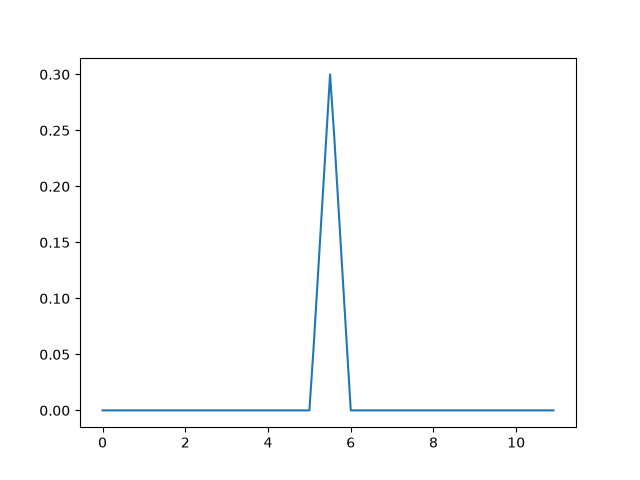

In [6]:
# Check code
fig_2, axs_2 = plt.subplots()
X_c2, Y_c2 = interpolate_road(X_r, Y_r, 10, 10)
axs_2.plot(X_c2, Y_c2)
plt.show()

In [7]:
grader.check("interpolate_road")

interpolate_road results: All test cases passed!

Now, use `interpolate_road` to find a `dt` where the bump in the road disappears. Graph your results.

Text(0.5, 1.0, 'Sampling w/ 100ms timesteps')

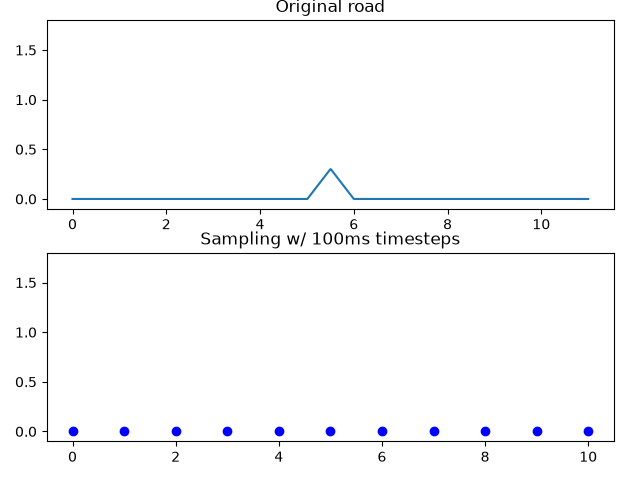

In [8]:
fig_no_bump, axs_no_bump = plt.subplots(2)
fig_no_bump.tight_layout()

# Average height of car is ~1.8m.
axs_no_bump[0].set_ylim(-0.1, 1.8)
axs_no_bump[1].set_ylim(-0.1, 1.8)

axs_no_bump[0].plot(X_r, Y_r)
axs_no_bump[0].set_title("Original road")

# GUIDES: Experiment with different dt values until the bump in the road goes away.
dt_2 = 100
(X_c3, Y_c3) = interpolate_road(X_r, Y_r, 10, dt_2)

# Plot points for car position -- blue circles
axs_no_bump[1].plot(X_c3, Y_c3, 'bo')
axs_no_bump[1].set_title(f"Sampling w/ {dt_2}ms timesteps")

In [9]:
grader.check("interpolate_road_2")

interpolate_road_2 results: All test cases passed!

## Part 2: The state space model for a quarter car

As mentioned above, a state space model is comprised of a set of differential equations describing the system. The equations are translated into a set of standard matrices that represent the system, which can then be passed into a solver.

We can express our quarter car as a set of differential equations, translate them into the standard matrices, and then simulate a quarter car traveling down arbitrary roads. These differential equations solve for the position of the sprung (car body) and unsprung (wheel) masses ($m_s$ and $m_u$) in the y direction over time as the car travels down the road.


### $y_s$: The y position of the sprung mass (car body)

The equations influencing the state space model of the quarter car follow from Newton's second law which states that:

$$F = ma$$

Although our car is traveling down the road in the $x$ direction, we are actually looking in the $y$ direction in our system as our car "bounces". Thus, in our case, $a$ can also be described as the second derivative of the $y$ position of an object, $\ddot{y}$.

So, for the sprung mass, we have:

$$F_s = m_s\ddot{y}$$

We actually have two forces at play on the sprung mass: $F_c$, the force of the damper; $F_k$, the force of the suspension's spring:

$$m_s\ddot{y} = F_c + F_k$$

$F_k$ is a spring, and its force comes from Hooke's Law:

$$F=-kx$$

...where $k$ is the spring constant and $x$ is the distance the spring is stretched or compressed from its equilibrium position. We can express the suspension spring's distance in terms of the $y$ position of the items bookending the spring, $y_s$ and $y_u$:

$$F_k = -k_{s}(y_s - y_u)$$

The damping force $F_c$ is expressed as:

$$F=-cv$$

...where $c$ is the damping coefficient and $v$ is the velocity of the object. The damper is directly attached to the sprung and unsprung masses, so its final velocity is relative to the velocity of those items in the y direction. Using $\dot{y}$ to indicate the velocity of an object in the $y$ direction, we have:

$$F_c = -c_{s}(\dot{y_s}-\dot{y_u})$$

Put it all together, and:

$$m_s\ddot{y_s} = -c_{s}(\dot{y_s}-\dot{y_u}) - k_{s}(y_s - y_u)$$

Solve for $\ddot{y_s}$, and you have:

$$\ddot{y_s} = \frac{-c_{s}(\dot{y_s}-\dot{y_u}) - k_{s}(y_s - y_u)}{m_s}$$

Move the terms around to express each term with relation to a $y$ variable, and you get:

$$\ddot{y_s} = \frac{k_s}{m_s}y_u + \frac{c_s}{m_s}\dot{y_u} + \frac{-k_s}{m_s}y_s + \frac{-c_s}{m_s}\dot{y_s}$$

### $y_u$: The y position of the unsprung mass (wheel)

The unsprung mass is below the suspension's damper and spring, which are pushng it down ($-F_c$, -$F_k$), and above the tire, which is acting like a spring and pushing it up ($F_t$). Put it together, and you have:

$$m_u\ddot{y_u} = - F_c - F_k + F_t$$

Similar to the process above, this breaks down to (where $y_r$ is the $y$ position of the road):

$$m_u\ddot{y_u} = c_{s}(\dot{y_s}-\dot{y_u}) + k_{s}(y_s - y_u) - k_{t}(y_u - y_r)$$

Like above, if we solve for $\ddot{y_u}$ and make all of the terms in relation to a $y$ variable, you get:

$$\ddot{y_u} = \frac{-(k_s + k_t)}{m_u}y_u + \frac{-c_s}{m_u}\dot{y_u} + \frac{k_{s}}{m_u}y_{s} + \frac{c_{s}}{m_u}\dot{y_{s}} + \frac{k_{t}}{m_u}y_{r}$$

### Translating into a state space model

The state space model contains four matrices that describe a system, although we only need to use three for this system:

* $A$: The _transition matrix_ which describes how changes in a state variable (the derivative of that variable) are influenced by other variables in the system.
* $B$: The _input matrix_, which describes how external factors affects each state variable. In the quarter car, the external factor is the $y$ position of the road.
* $C$: The _output matrix_ determines the relationship between the internal state variables and the output we want from the system.
* $D$: Describes how the input directly influences the system's output, which is not relevant for this system.

#### $A$: The transition matrix

The transition matrix is the heart of our system. From our equations, the state variables in our system are:

1. $y_u$, the y position of the unsprung mass.
2. $\dot{y_u}$, the y velocity of the unsprung mass.
3. $y_s$, the y position of the sprung mass.
4. $\dot{y_s}$, the y velocity of the sprung mass.

_(Note to astute readers: $y_r$ in the equations is an external variable; we will get to it when we discuss the $B$ matrix.)_

Each entry in $A$ describes the relationship between a specific state variable and its derivative:

| | $y_u$ | $\dot{y_u}$ | $y_s$ | $\dot{y_s}$ |
|-|-------|-----------|-------|-------------|
|$\dot{y_u}$ | |
|$\ddot{y_u}$ |
|$\dot{y_s}$ |
|$\ddot{y_s}$ |

As you can see, some of the derivatives of our state variables actually directly correspond to other state variables! Since $\dot{y_u} = \dot{y_u}$ and $\dot{y_s} = \dot{y_s}$, we can put a $1$ in the matrix entries since $\dot{y_u} = 1*\dot{y_u}$:

| | $y_u$ | $\dot{y_u}$ | $y_s$ | $\dot{y_s}$ |
|-|-------|-----------|-------|-------------|
|$\dot{y_u}$ | | 1 |
|$\ddot{y_u}$ |
|$\dot{y_s}$ | | | | 1 |
|$\ddot{y_s}$ |

Also, the position of an object has no influence over its velocity; it's the other way around. And the position of the unsprung mass has no direct bearing on the sprung mass's velocity or position. So, we can plug in a few 0s:

| | $y_u$ | $\dot{y_u}$ | $y_s$ | $\dot{y_s}$ |
|-|-------|-----------|-------|-------------|
|$\dot{y_u}$ | 0 | 1 | 0 | 0 |
|$\ddot{y_u}$ |
|$\dot{y_s}$ | 0 | 0 | 0 | 1 |
|$\ddot{y_s}$ |

The remaining rows are more interesting. If you recall from above, we solved for $\ddot{y_u}$ and $\ddot{y_s}$ in terms of the other state variables:

$$\ddot{y_u} = \frac{-(k_s + k_t)}{m_u}y_u + \frac{-c_s}{m_u}\dot{y_u} + \frac{k_{s}}{m_u}y_{s} + \frac{c_{s}}{m_u}\dot{y_{s}} + \frac{k_{t}}{m_u}y_{r}$$

$$\ddot{y_s} = \frac{k_s}{m_s}y_u + \frac{c_s}{m_s}\dot{y_u} + \frac{-k_s}{m_s}y_s + \frac{-c_s}{m_s}\dot{y_s}$$

Ignoring terms for the external variable $y_r$, we can plug all of the above into the matrix to get:

| | $y_u$ | $\dot{y_u}$ | $y_s$ | $\dot{y_s}$ |
|-|-------|-----------|-------|-------------|
|$\dot{y_u}$ | 0 | 1 | 0 | 0 |
|$\ddot{y_u}$ | $\frac{-(k_s + k_t)}{m_u}$ | $\frac{-c_s}{m_u}$ | $\frac{k_{s}}{m_u}$ | $\frac{c_{s}}{m_u}$ | 
|$\dot{y_s}$ | 0 | 0 | 0 | 1 |
|$\ddot{y_s}$ | $\frac{k_s}{m_s}$ | $\frac{c_s}{m_s}$ | $\frac{-k_s}{m_s}$ | $\frac{-c_s}{m_s}$ |


#### $B$: The _input matrix_

$B$ describes the relationship of external variables to changes in the input variables. Our system has one external variable; $y_r$, the y position of the road; so $B$ looks like this:

| | $y_r$ |
|-|-------|
|$\dot{y_u}$ |
|$\ddot{y_u}$ |
|$\dot{y_s}$ |
|$\ddot{y_s}$ |

Our equations above only have one term with relation to $y_r$:

$$\ddot{y_u} = \ldots + \frac{k_{t}}{m_u}y_{r}$$

So, our $B$ matrix is:

| | $y_r$ |
|-|-------|
|$\dot{y_u}$ | 0 |
|$\ddot{y_u}$ | $\frac{k_t}{m_u}$ |
|$\dot{y_s}$ | 0 |
|$\ddot{y_s}$ | 0 |

#### $C$: The _output matrix_

The _output matrix_ describes the relationship between the internal state variables and the output we want from the system. For our animation, we need $y_u$ and $y_s$, the positions of the sprung and unsprung masses. Those are our _output variables_, which happen to directly correspond to input variables!

So, our $C$ matrix is:

| | $y_u$ | $\dot{y_u}$ | $y_s$ | $\dot{y_s}$ |
|-|-------|-----------|-------|-------------|
| $y_u$ | 1 | 0 | 0 | 0 |
| $y_s$ | 0 | 0 | 1 | 0 |

#### $D$: How input influences output

$D$ describes how our input variable ($y_r$) directly impacts change in output variables ($\dot{y_u}$ and $\dot{y_s}$). Our system is simple, in that our output variables are actually the same as state variables, so $B$ actually captures all that we need here.

Thus, $D$ is all zeroes:

| | $y_r$ |
|-|-------|
| $\dot{y_u}$ | 0 |
| $\dot{y_s}$ | 0 |

### Translating the state space model into Python

In Python, Scipy has direct support for solving state space systems. In this lab, you will add the $A$, $B$, $C$, and $D$ matrices and a `simulate` method to the **`QuarterCar` class in `car.py`**.

Now we know:

* How to break up a road (a line) into discrete points.
* How to express the system as a state space system

`simulate` should store the results on the quarter car itself (`self.time`, `self.y_s`, `self.y_u`, `self.x_r`, `self.y_r`, ...). There is no separate output class.

**Before you implement `simulate`:** copy your working `interpolate_road` from this notebook into `car.py` (the `# TODO Lab 6` block). `QuarterCar.simulate` calls the copy in `car.py`.


In [10]:
# GUIDES Lab 6:
# 1. Copy interpolate_road from this notebook into car.py (keep the notebook version too; it is what this lab grades).
# 2. In QuarterCar.__init__ in car.py, store m_s, m_u, c_s, k_s, k_t on self (Lab 6 TODO).
# 3. Implement QuarterCar.A and QuarterCar.B in car.py. C and D are given.
# 4. Implement QuarterCar.simulate in car.py so it uses interpolate_road from car.py and stores
#    velocity, time, dt, x_r, y_s, y_u, y_r on self (and return self).
from car import QuarterCar


# No need to paste draw_* from Lab 5 — they already live in car.py.
# No need to paste QuarterCar from Lab 5

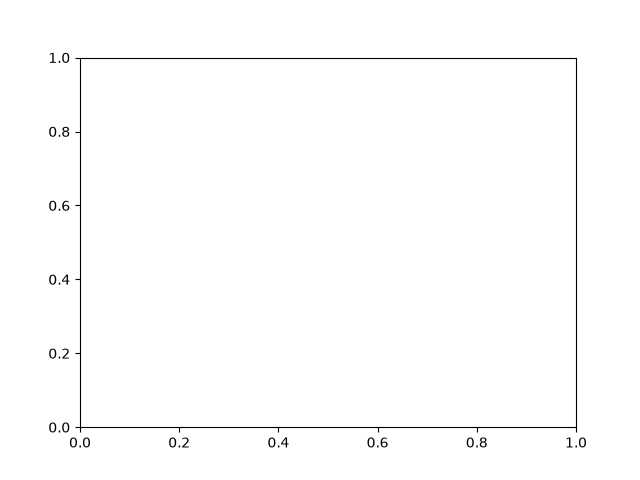

In [11]:
car = QuarterCar()
car.simulate(velocity=10, dt=10, x_r=X_r, y_r=Y_r)

fig_anim, axs_anim = plt.subplots()

# The x/y axes are like our camera.
#
# We want the y limit to be big enough to show the road, the height of the car, and some extra buffer above the car.
# For the y limit, find the peak in the road and add twice the car's static height.
y_lim_max = np.max(Y_r) + (car.y_s_static*2)
# We want the x limit to show the full length of the car plus a buffer, and change its offset depending on the
# car's position. We accomplish this goal by setting it to 2x the car's width.
x_size_max = car.w_s * 2

# We want the size of the x and y axs to be the same so the aspect ratio of the output isn't squished.
fig_width_and_height = max(y_lim_max, x_size_max)


def draw_car_frame(i):
    """
    Draws frame `i` of our animation into axs_anim.
    @param i Integer indicating which frame of the animation we are on.
    """
    axs_anim.clear()
    # Set the y limit just a little below 0 so we see the road line at y=0.
    axs_anim.set_ylim([-0.1, fig_width_and_height])
    # Center the camera on the car's current x position on the road.
    axs_anim.set_xlim([car.x_r[i] - (fig_width_and_height / 2), car.x_r[i] + (fig_width_and_height / 2)])
    # Draw the original road line, not car.x_r. car.x_r is sampled.
    axs_anim.plot(X_r, Y_r, 'k')
    car.draw(axs=axs_anim, x=car.x_r[i], y_s=car.y_s[i], y_u=car.y_u[i], y_r=car.y_r[i])

# Play the animation at half speed.
playback_speed = 0.5
# We disable repeats for animations because the animation will repeat forever, which can cause issues when re-running a cell.
anim = animation.FuncAnimation(fig_anim, draw_car_frame, frames=len(car.x_r), interval=car.dt / playback_speed, repeat=False)
plt.show()


In [12]:
grader.check("state_space_model")

state_space_model results: All test cases passed!

<!-- BEGIN QUESTION -->

## Part 3: Experimenting with `dt` 
Now we have a way to simulate quarter cars on arbitrary roads!

First, let's generalize the animation function so that you can easily animate new cars.

In [13]:
def animate_car(car, velocity, dt, x_r, y_r, playback_speed=1.0):
    """
    Animate the given car going down the given road.
    @param car The `QuarterCar` to simulate and draw.
    @param velocity The velocity of the quarter car in the x direction in m/s.
    @param dt The time step of the simulation
    @param x_r, y_r The x and y coordinates of the road.
    @param playback_speed A value that is > 0 that indicates the playback speed (e.g., 0.1 is 10x slowdown).
    @return The animation object from animation.Funcanimation.
    """
    # GUIDES: Define function
    car.simulate(velocity, dt, x_r, y_r)
    anim = animation.FuncAnimation(fig_anim, draw_car_frame, frames=len(car.x_r), interval=car.dt / playback_speed, repeat=False)
    return anim



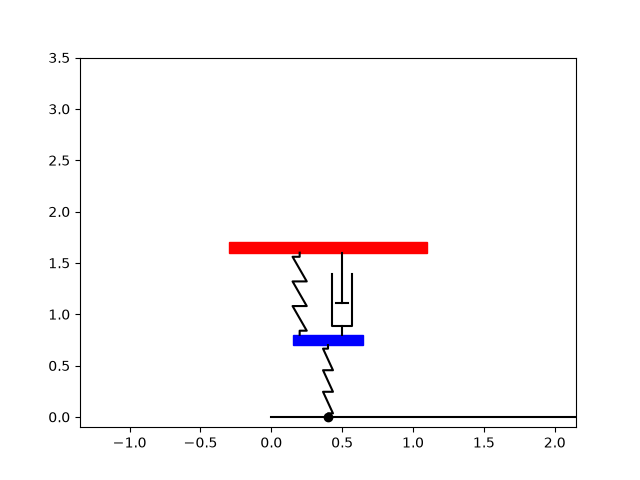

In [14]:
# This should work.
#
# Although we don't do anything with `anim`, if we don't save it into a variable,
# Python will delete it before it animates. Saving it into a variable tells Python to
# keep it around to animate.
#
# If your animation isn't working, make sure you are returning the animation in your function!
anim = animate_car(car=car, velocity=10, dt=10, x_r=X_r, y_r=Y_r, playback_speed=0.5)
plt.show()


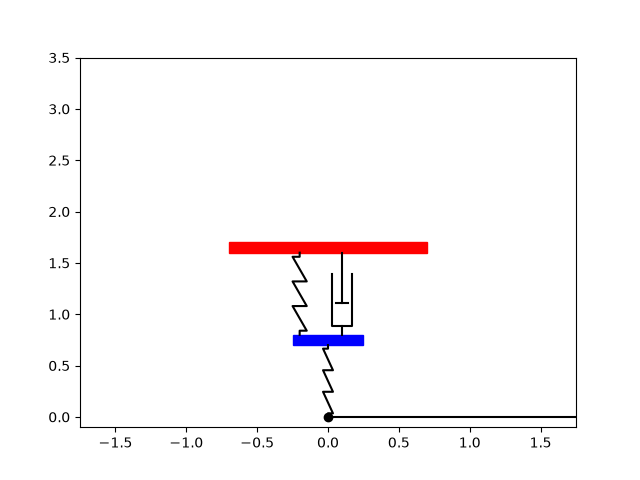

In [15]:
# Next, let's try simulating the same quarter car on the same road, 
#  but with the large `dt` value that you used previously. 
#  You will notice that the car does not react to the bump because the simulation did not "see" the bump!
# 
# GUIDES: Animate car with the large timestamp that misses the bump.
anim_2 = animate_car(car=car, velocity=10, dt=100, x_r=X_r, y_r=Y_r, playback_speed=0.5)
plt.show()

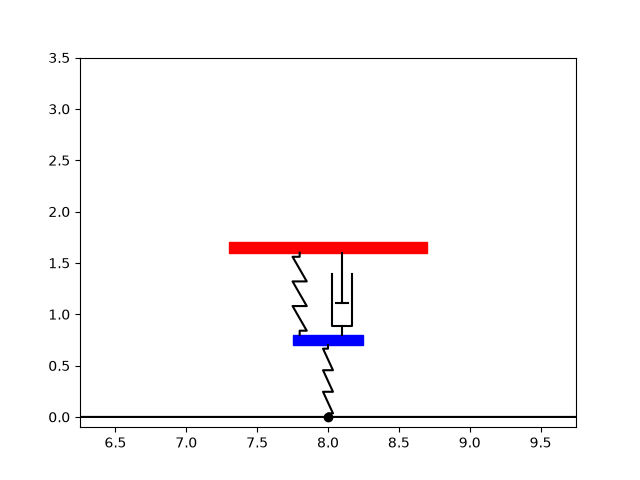

In [16]:
# Now, let's try the same simulation, but make `dt` very small. 
# What ends up happening? Does your animation complete?
# 
# GUIDES: animate car with a small timestamp.
anim_3 = animate_car(car=car, velocity=1, dt=1, x_r=X_r, y_r=Y_r, playback_speed=0.5)
plt.show()

In [17]:
print("This is a manually-graded question; there is no grader.check() function. See rubric and slides for more information on expected output.")

This is a manually-graded question; there is no grader.check() function. See rubric and slides for more information on expected output.


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

# Part 4: Playing with the simulation

Now we have a way to simulate and animate a quarter car. Your job now is to define a road that makes the simulation go haywire. And by haywire, we mean that the car enters a state during the animation where it is drawn incorrectly (unsprung mass over sprung mass, damper poking through a mass, etc).

In [18]:
# GUIDES: Define a road in X_r_haywire and Y_r_haywire that makes the simulation go haywire.
# Like with the previous road, you may need to define it in multiple segments
# and combine them together.
#
# Show your animation to a TA for signoff, and explain what you did.

X_r_haywire = [1, 2, 3, 4, 4, 5, 7, 8, 9, 10]
Y_r_haywire = [1, 1, 1, 3, 3, 1, 1, 1, 1, 1]


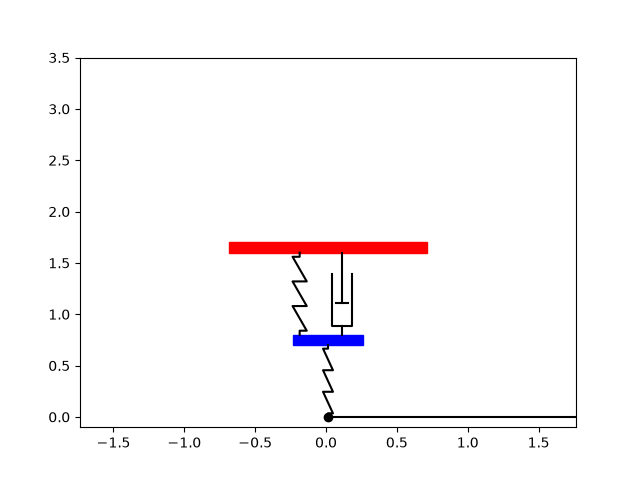

In [19]:
anim = animate_car(car=car, velocity=10, dt=10, x_r=X_r_haywire, y_r=Y_r_haywire, playback_speed=0.5)
plt.show()


In [20]:
print("This is a manually-graded question; there is no grader.check() function. See rubric and slides for more information on expected output.")

This is a manually-graded question; there is no grader.check() function. See rubric and slides for more information on expected output.


<!-- END QUESTION -->

## Hours and collaborators
Required for every assignment - fill out before you hand-in.

Listing names and websites helps you to document who you worked with and what internet help you received in the case of any plagiarism issues. You should list names of anyone (in class or not) who has substantially helped you with an assignment - or anyone you have *helped*. You do not need to list TAs.

Listing hours helps us track if the assignments are too long.

In [21]:
import os

# List of names (creates a set)
worked_with_names = {"By Myself"}
# List of URLS FA26 (creates a set)
websites = {"https://www.w3schools.com/python/scipy/scipy_interpolation.php"}
# Approximate number of hours, including lab/in-class time
hours = 4

# VS Code stores the path in a special global variable
if '__vsc_ipynb_file__' in globals():
    notebook_path = globals()['__vsc_ipynb_file__']
    notebook_name = os.path.basename(notebook_path)
    json_name = notebook_name[:-6] + "_source.json"
    if not os.path.exists(json_name):
        print(f"Could not find the json file {json_name}; make sure the required VSCode extension is installed and running")


In [22]:
grader.check("hours_collaborators")

hours_collaborators results: All test cases passed!

### To submit

Double check your plots.

- Submit this .ipynb file, the .json file, and **`car.py`** through Gradescope, to Lab 6 (simulating quarter car)

Failures: None expected
